<a href="https://colab.research.google.com/github/yousufapel785-lab/DhakaRentAI/blob/master/Neighborhood_aware_IQR%2BTwo_stage_XGBoost_Fine_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# NEIGHBORHOOD-AWARE IQR + TWO-STAGE XGBOOST FINE-TUNING


import numpy as np
import pandas as pd
import re

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from xgboost import XGBRegressor


# 1. LOAD AND CLEAN DATA


df = pd.read_csv("houserentdhaka.csv")


def clean_price(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().replace(",", "").strip()
    number = re.search(r"\d+(?:\.\d+)?", text)

    if not number:
        return np.nan

    number = float(number.group())

    if "lakh" in text:
        return number * 100000
    if "thousand" in text:
        return number * 1000

    return number


def clean_area(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().replace(",", "").strip()

    area_range = re.search(
        r"(\d+(?:\.\d+)?)\s*[-–]\s*(\d+(?:\.\d+)?)",
        text
    )

    if area_range:
        return (
            float(area_range.group(1)) +
            float(area_range.group(2))
        ) / 2

    number = re.search(r"\d+(?:\.\d+)?", text)

    return float(number.group()) if number else np.nan


df["Price"] = df["Price"].apply(clean_price)
df["Area"] = df["Area"].apply(clean_area)

df = df.dropna(
    subset=["Location", "Area", "Bed", "Bath", "Price"]
).copy()

df = df[
    (df["Price"] > 0) &
    (df["Area"] > 0) &
    (df["Bed"] >= 0) &
    (df["Bath"] >= 0)
].reset_index(drop=True)


# 2. LOCATION PROCESSING


def extract_neighborhood(location):
    parts = [
        p.strip().lower()
        for p in str(location).split(",")
        if p.strip()
    ]

    return parts[-2] if len(parts) >= 2 else parts[0]


df["Clean_Location"] = df["Location"].apply(
    extract_neighborhood
)

location_counts = df["Clean_Location"].value_counts()

top_locations = location_counts[
    location_counts >= 10
].index

df["Clean_Location"] = df["Clean_Location"].apply(
    lambda x: x if x in top_locations else "other"
)


# 3. FEATURE ENGINEERING


df["Space_per_Bed"] = (
    df["Area"] / df["Bed"].replace(0, 1)
)

df["Bed_Bath_Ratio"] = (
    df["Bed"] / df["Bath"].replace(0, 1)
)

df["Total_Rooms"] = (
    df["Bed"] + df["Bath"]
)

df["Area_per_Room"] = (
    df["Area"] /
    df["Total_Rooms"].replace(0, 1)
)

df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

df.dropna(
    subset=[
        "Space_per_Bed",
        "Bed_Bath_Ratio",
        "Area_per_Room"
    ],
    inplace=True
)


# 4. NEIGHBORHOOD-AWARE IQR FILTERING


cleaned_groups = []

for location, group in df.groupby("Clean_Location"):

    group = group.copy()

    if len(group) >= 10:

        for column in ["Area", "Price"]:

            Q1 = group[column].quantile(0.25)
            Q3 = group[column].quantile(0.75)
            IQR = Q3 - Q1

            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR

            group = group[
                (group[column] >= lower_bound) &
                (group[column] <= upper_bound)
            ]

    cleaned_groups.append(group)


df_final = pd.concat(
    cleaned_groups,
    ignore_index=True
)

print("Original Dataset:", df.shape)
print("After IQR Filtering:", df_final.shape)


# 5. FEATURES AND TARGET


features = [
    "Area",
    "Bed",
    "Bath",
    "Clean_Location",
    "Space_per_Bed",
    "Bed_Bath_Ratio",
    "Total_Rooms",
    "Area_per_Room"
]

X = df_final[features]
y = df_final["Price"]


# 6. TRAIN-TEST SPLIT


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Log transformation of the target variable
y_train_log = np.log1p(y_train)



# 7. PREPROCESSING


categorical_features = ["Clean_Location"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "location",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


# 8. STAGE 1: RANDOMIZED SEARCH


xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

stage1_params = {
    "n_estimators": [300, 500, 700, 900],
    "learning_rate": [0.01, 0.03, 0.05, 0.08],
    "max_depth": [3, 4, 5, 6, 7, 8],
    "min_child_weight": [1, 2, 3, 5],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

stage1_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=stage1_params,
    n_iter=30,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

stage1_search.fit(
    X_train_processed,
    y_train_log
)

print("\nStage 1 Best Parameters:")
print(stage1_search.best_params_)

print(
    "Stage 1 Best CV R2:",
    round(stage1_search.best_score_, 4)
)

# 9. STAGE 2: FINE GRID SEARCH


best = stage1_search.best_params_

stage2_params = {
    "n_estimators": [
        max(100, best["n_estimators"] - 100),
        best["n_estimators"],
        best["n_estimators"] + 100
    ],
    "learning_rate": [
        max(0.01, best["learning_rate"] - 0.01),
        best["learning_rate"],
        best["learning_rate"] + 0.01
    ],
    "max_depth": [
        max(2, best["max_depth"] - 1),
        best["max_depth"],
        best["max_depth"] + 1
    ],
    "min_child_weight": [
        max(1, best["min_child_weight"] - 1),
        best["min_child_weight"],
        best["min_child_weight"] + 1
    ]
}

stage2_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=stage2_params,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

stage2_search.fit(
    X_train_processed,
    y_train_log
)

tuned_xgb = stage2_search.best_estimator_

print("\nStage 2 Best Parameters:")
print(stage2_search.best_params_)

print(
    "Stage 2 Best CV R2:",
    round(stage2_search.best_score_, 4)
)



#9. STAGE 2: FINE GRID SEARCH


rf_base = RandomForestRegressor(
    n_estimators=500,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

gb_base = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.9,
    random_state=42
)


# 11. PROPOSED STACKING ENSEMBLE


meta_learner = Ridge(alpha=1.0)

stacking_model = StackingRegressor(
    estimators=[
        ("rf", rf_base),
        ("xgb", tuned_xgb),
        ("gb", gb_base)
    ],
    final_estimator=meta_learner,
    cv=5,
    n_jobs=-1
)


# 12. MODEL EVALUATION


models = {
    "Random Forest Regressor": rf_base,
    "Tuned XGBoost Regressor": tuned_xgb,
    "Gradient Boosting Regressor": gb_base,
    "Proposed Stacking Ensemble": stacking_model
}

results = {}

for name, model in models.items():

    model.fit(
        X_train_processed,
        y_train_log
    )

    pred_log = model.predict(
        X_test_processed
    )

    # Convert predictions back to original BDT scale
    pred = np.maximum(
        np.expm1(pred_log),
        0
    )

    results[name] = {
        "R2 Score": r2_score(y_test, pred),
        "MAE (BDT)": mean_absolute_error(
            y_test,
            pred
        ),
        "RMSE (BDT)": np.sqrt(
            mean_squared_error(
                y_test,
                pred
            )
        )
    }


# 13. FINAL PERFORMANCE COMPARISON


df_results = pd.DataFrame(
    results
).T.sort_values(
    by="R2 Score",
    ascending=False
)

print("\n" + "=" * 70)
print("FINAL MODEL PERFORMANCE — TWO-STAGE FINE-TUNING")
print("=" * 70)
print(df_results.to_string())
print("=" * 70)

best_model = df_results.index[0]

print(
    f"\nBest Model: {best_model}"
)

print(
    f"R2 Score: "
    f"{df_results.loc[best_model, 'R2 Score']:.4f}"
)

print(
    f"R2 Percentage: "
    f"{df_results.loc[best_model, 'R2 Score'] * 100:.2f}%"
)

df_results.to_csv(
    "code2_two_stage_tuning_results.csv"
)

Original Dataset: (28800, 11)
After IQR Filtering: (26769, 11)
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Stage 1 Best Parameters:
{'subsample': 0.9, 'n_estimators': 700, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Stage 1 Best CV R2: 0.888
Fitting 5 folds for each of 81 candidates, totalling 405 fits

Stage 2 Best Parameters:
{'learning_rate': 0.05, 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 800}
Stage 2 Best CV R2: 0.8878

FINAL MODEL PERFORMANCE — TWO-STAGE FINE-TUNING
                             R2 Score    MAE (BDT)   RMSE (BDT)
Proposed Stacking Ensemble   0.885071  2416.407366  5548.663244
Tuned XGBoost Regressor      0.883034  2429.002424  5597.625936
Gradient Boosting Regressor  0.882372  2617.508352  5613.440894
Random Forest Regressor      0.873358  2431.144975  5824.572741

Best Model: Proposed Stacking Ensemble
R2 Score: 0.8851
R2 Percentage: 88.51%


In [ ]:
pip install matplotlib seaborn shap

/tmp/ipykernel_19632/2125341823.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


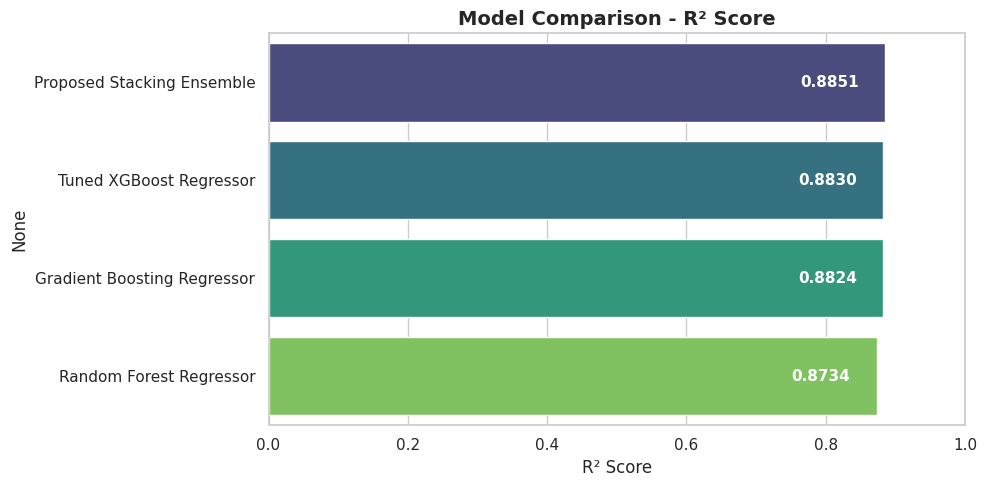

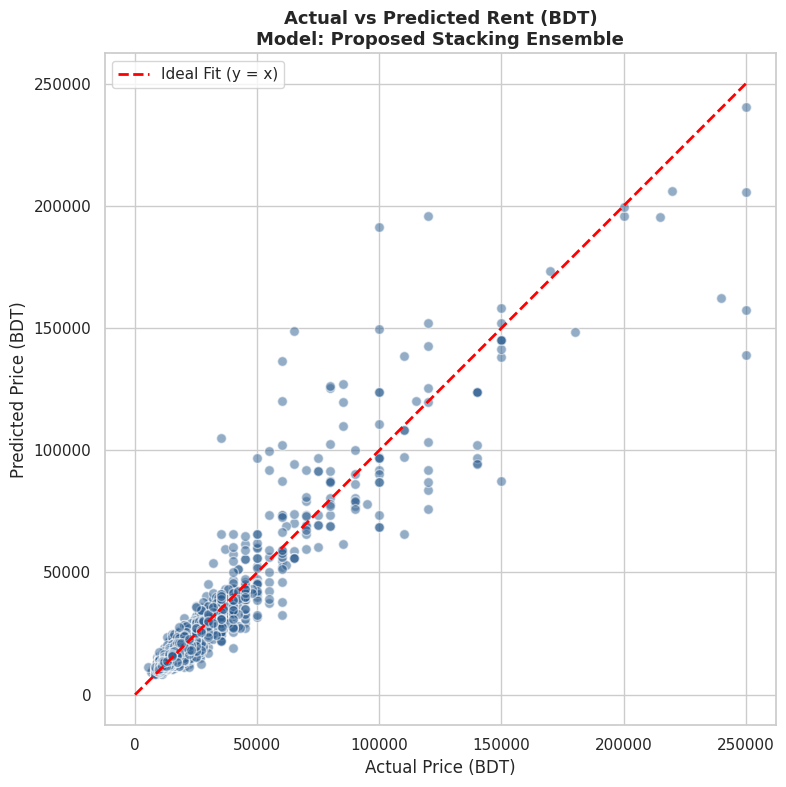

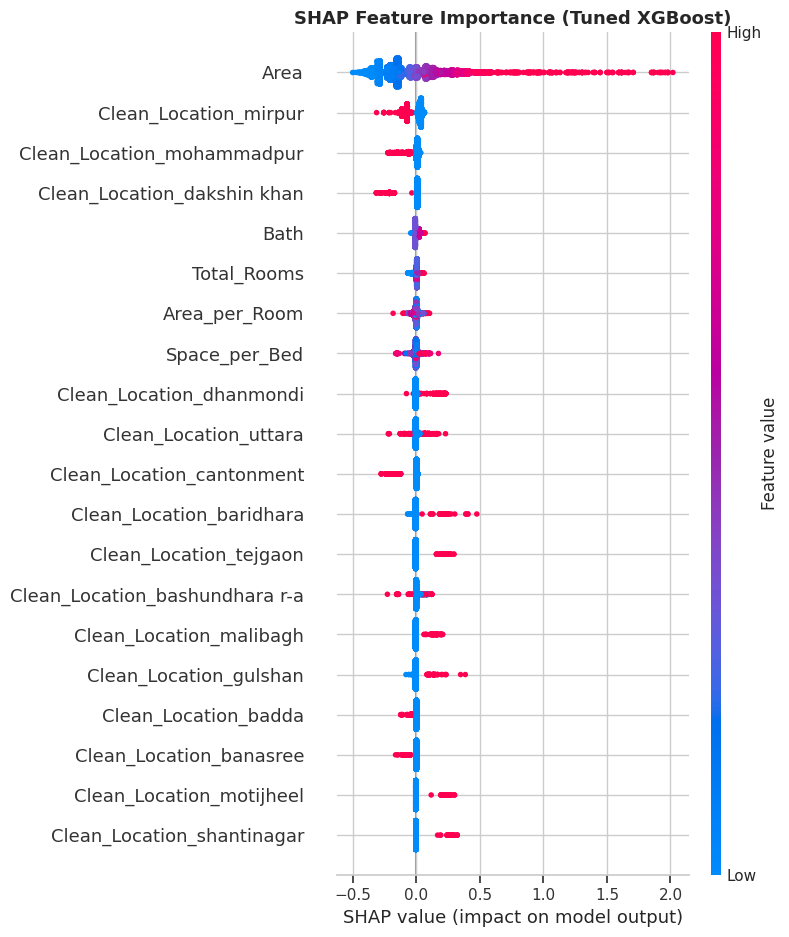

In [ ]:
# ============================================================
# 14. VISUALIZATIONS: MODEL COMPARISON, SCATTER PLOT, SHAP
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import shap

# Set cohesive visual styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11})

# ------------------------------------------------------------
# A. MODEL COMPARISON BAR CHART
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=df_results["R2 Score"],
    y=df_results.index,
    palette="viridis",
    ax=ax
)
ax.set_title("Model Comparison - R² Score", fontsize=14, fontweight="bold")
ax.set_xlabel("R² Score")
ax.set_xlim(0, 1)

# Annotate values onto bars
for bar in ax.patches:
    width = bar.get_width()
    ax.text(
        width - 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# B. ACTUAL VS PREDICTED SCATTER PLOT (Best Model)
# ------------------------------------------------------------
# Retrieve the winning model object
best_model_name = df_results.index[0]
best_model_obj = models[best_model_name]

# Generate predictions for the scatter plot
best_pred_log = best_model_obj.predict(X_test_processed)
best_pred = np.maximum(np.expm1(best_pred_log), 0)

plt.figure(figsize=(8, 8))
plt.scatter(y_test, best_pred, alpha=0.5, color="#2b5c8f", edgecolors="w", s=50)

# Ideal reference line (y = x)
max_val = max(y_test.max(), best_pred.max())
plt.plot([0, max_val], [0, max_val], color="red", linestyle="--", linewidth=2, label="Ideal Fit (y = x)")

plt.title(f"Actual vs Predicted Rent (BDT)\nModel: {best_model_name}", fontsize=13, fontweight="bold")
plt.xlabel("Actual Price (BDT)", fontsize=12)
plt.ylabel("Predicted Price (BDT)", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# C. SHAP FEATURE IMPORTANCE (Tuned XGBoost)
# ------------------------------------------------------------
# Extract feature names after OneHotEncoding
ohe_feature_names = list(
    preprocessor.named_transformers_["location"].get_feature_names_out(categorical_features)
)
numeric_features = [f for f in features if f not in categorical_features]
all_feature_names = ohe_feature_names + numeric_features

# Convert transformed numpy array to DataFrame with feature names
X_test_df = pd.DataFrame(X_test_processed, columns=all_feature_names)

# Compute SHAP values for XGBoost
explainer = shap.TreeExplainer(tuned_xgb)
shap_values = explainer(X_test_df)

plt.figure(figsize=(10, 6))
plt.title("SHAP Feature Importance (Tuned XGBoost)", fontsize=13, fontweight="bold")
shap.summary_plot(shap_values, X_test_df, show=True)

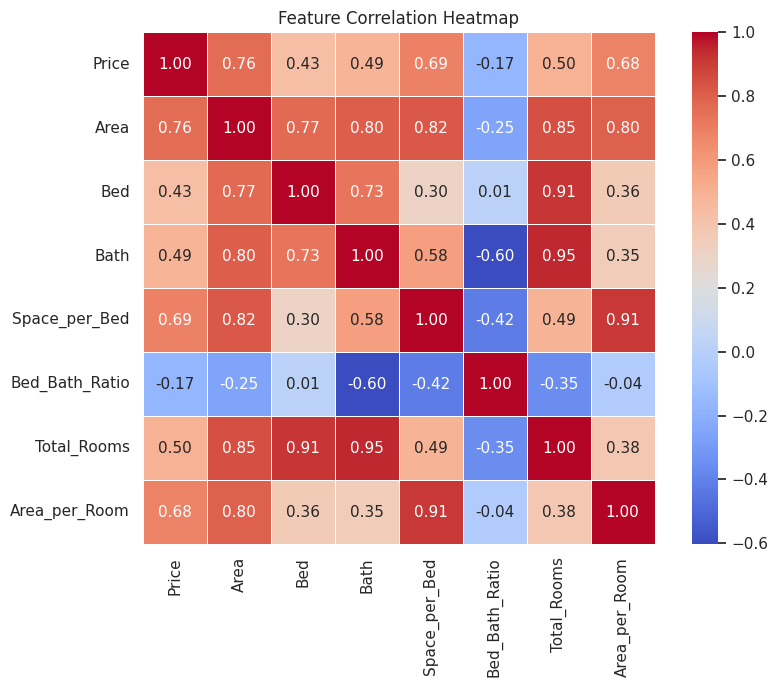

In [ ]:
# ============================================================
# FIGURE 4: Correlation Heatmap
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9,7))

corr_cols = [
    'Price',
    'Area',
    'Bed',
    'Bath',
    'Space_per_Bed',
    'Bed_Bath_Ratio',
    'Total_Rooms',
    'Area_per_Room'
]

corr_matrix = df_final[corr_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("Figure_1_Correlation_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()